# GreenMove — Voir le code **ET** le résultat ensemble

**Démonstration technique des dossiers 4 et 5** · Les moteurs Python sont ceux des ZIP, sans modification.

**Méthode de présentation :** dans chaque étape, tu vois à gauche **la véritable fonction Python du projet**, et à droite **son résultat calculé à partir des données**. Le code de la cellule, juste au-dessus, appelle cette fonction.

> Pour présenter : **Ctrl+B** pour masquer l'explorateur → clique sur ▶ à gauche de la cellule → commente le code et le schéma côte à côte. Ne lance pas « Run All » pendant la vidéo.

| Étape | Code réel affiché | Preuve graphique |
| --- | --- | --- |
| 1 | `calculate_bounding_box()` | Rectangle ZFE construit avec les coordonnées min/max |
| 2 | `is_point_inside_polygon()` | Pourquoi le point GPS 3 est OUT |
| 3 | `is_point_inside_polygon()` | Pourquoi le point GPS 4 est IN |
| 4 | `run_geo_engine()` | Une seule alerte lors de l'entrée |
| 5 | `is_harsh_braking()` et `analyze_accelerometer_stream()` | Freinage −3,45 m/s² |
| 6 | `generate_demo_data()` | 1 000 mesures simulées à 100 Hz |
| 7 | `SyncService.sync_pending()` | SQLite : attente pendant la coupure, reprise simulée |
| 8 | `load_json_file()` | Gestion d'un fichier manquant |

**Limites à annoncer :** acquisition GPS et accéléromètre simulée, pas de filtre passe-bas actuel, matériel Zebra non testé, synchronisation réseau simulée. Le stockage SQLite est réel.

In [1]:
# CELLULE D'INITIALISATION — exécute-la une seule fois
from pathlib import Path
import os, sys, inspect, io, base64, html, tempfile
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from IPython.display import HTML, display
from contextlib import redirect_stdout

ROOT = Path.cwd()
assert (ROOT/'src/geo/geo_engine.py').exists() and (ROOT/'data/lyon_polygon.json').exists(), (
    'Ouvre le DOSSIER GreenMove_Demo_Code_et_Resultats dans VS Code, pas seulement le fichier .ipynb.'
)
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.geo.geo_engine import (load_json_file, calculate_bounding_box, is_inside_bounding_box,
                                 is_point_inside_polygon, is_point_in_zfe)
from src.geo.run_geo import run_geo_engine
from src.safety.safety_engine import (iter_accelerometer_data, is_harsh_braking,
                                       analyze_accelerometer_stream, HARSH_BRAKING_THRESHOLD)
from scripts.generate_demo_data import generate_demo_data
from src.storage.event_repository import EventRepository
from src.domain.telemetry_event import TelemetryEvent
from src.sync.sync_service import SyncService

polygon = load_json_file('data/lyon_polygon.json')
gps_points = load_json_file('data/truck_gps.json')
bbox = calculate_bounding_box(polygon)
samples = list(iter_accelerometer_data('data/accelerometer_data.csv'))

# Cette fonction sert uniquement à la présentation : elle affiche le SOURCE du projet à gauche
# et le graphique obtenu par son exécution à droite. Elle ne remplace aucun calcul métier.
def code_et_resultat(fonctions, figure, resultat, titre):
    if not isinstance(fonctions, (list, tuple)): fonctions=[fonctions]
    vrai_code = '\n\n'.join(inspect.getsource(f) for f in fonctions)
    image = io.BytesIO()
    figure.savefig(image, format='png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.close(figure)
    encoded=base64.b64encode(image.getvalue()).decode('ascii')
    title=html.escape(titre)
    display(HTML(f"""<div style="font-family:Segoe UI,Arial,sans-serif;max-width:1300px;">
      <h2 style="color:#ea580c;border-bottom:3px solid #ea580c;padding-bottom:10px">{title}</h2>
      <div style="display:flex;align-items:stretch;gap:15px;flex-wrap:wrap;">
        <div style="flex:1 1 375px;min-width:290px;border:1px solid #b5bbc5;border-radius:9px;overflow:hidden;">
          <div style="background:#182336;color:white;padding:12px;font-size:16px;font-weight:bold">1 · CODE RÉEL DU PROJET</div>
          <pre style="background:#101827;color:#f1f5f9;font-size:12px;line-height:1.5;margin:0;padding:13px;max-height:390px;overflow:auto;white-space:pre">{html.escape(vrai_code)}</pre>
        </div>
        <div style="flex:1.3 1 460px;min-width:310px;border:1px solid #b5bbc5;border-radius:9px;overflow:hidden;">
          <div style="background:#ea580c;color:white;padding:12px;font-size:16px;font-weight:bold">2 · RÉSULTAT CALCULÉ</div>
          <img src="data:image/png;base64,{encoded}" style="width:100%;height:auto;display:block"/>
          <div style="background:#fff4ea;color:#542407;padding:13px;font-weight:bold;font-size:16px">{resultat}</div>
        </div>
      </div>
      <p style="font-size:12px;color:#64748b;margin-top:8px">Source du code : inspect.getsource() sur les fonctions originales dans src/. Le graphique est une visualisation des données de ces fonctions.</p>
    </div>"""))

# Graphiques : uniquement des fonctions d'affichage, ne modifient pas la décision Python.
def fond_polygon(ax):
    coord=[(p['lon'],p['lat']) for p in polygon]
    ax.add_patch(Polygon(coord,closed=True,facecolor='#ffedd5',edgecolor='#ea580c',lw=2.2))
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.grid(alpha=.15); ax.set_axisbelow(True)
    ax.set_xlim(4.743,4.885); ax.set_ylim(45.725,45.817)
    ax.set_aspect('auto')

# Pour voir le détail du Ray Casting sans toucher à son implémentation,
# recalcul graphique des intersections sur la même géométrie : la décision reste celle de la fonction du projet.
def intersections_pour_dessin(point):
    x,y=point['lon'],point['lat']; xs=[]
    prev=polygon[-1]
    for cur in polygon:
        if ((cur['lat']>y)!=(prev['lat']>y)):
            xinter=(prev['lon']-cur['lon'])*(y-cur['lat'])/(prev['lat']-cur['lat'])+cur['lon']
            if x<xinter: xs.append(xinter)
        prev=cur
    return xs
print('PRÊT — fonctions originales importées depuis src/ ; 5 positions GPS et 10 mesures chargées.')

PRÊT — fonctions originales importées depuis src/ ; 5 positions GPS et 10 mesures chargées.


## 1 — Bounding Box : d'où vient le rectangle ?

**Dans le code :** `calculate_bounding_box(polygon)` reçoit les sommets de `lyon_polygon.json` et calcule les quatre bornes. **Dans le schéma :** le rectangle bleu est construit avec ces quatre bornes ; les points sont issus de `truck_gps.json`.


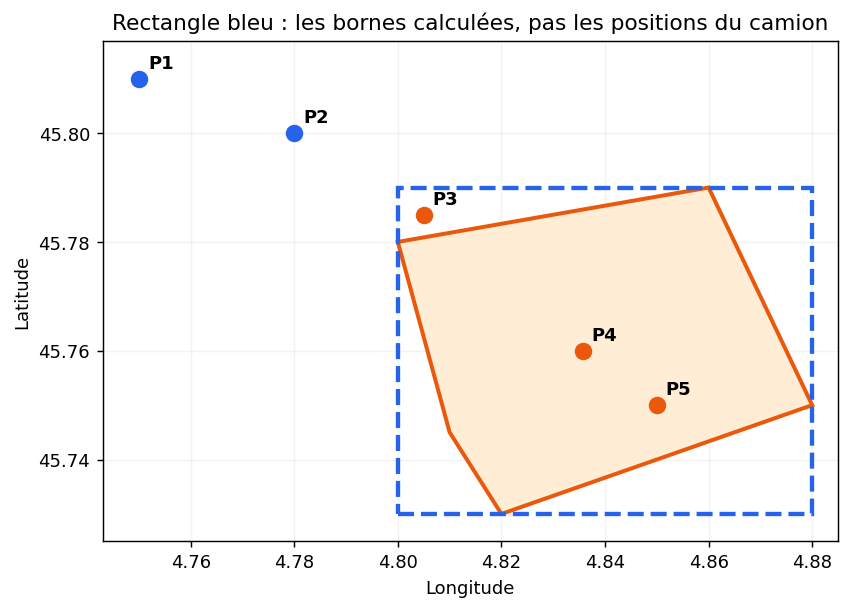

In [2]:
# Le calcul métier vient de src/geo/geo_engine.py ; voici l'appel réel.
bbox = calculate_bounding_box(polygon)
fig, ax=plt.subplots(figsize=(7.3,5))
fond_polygon(ax)
ax.add_patch(Rectangle((bbox['min_lon'],bbox['min_lat']),
                       bbox['max_lon']-bbox['min_lon'],bbox['max_lat']-bbox['min_lat'],
                       fill=False,edgecolor='#2563eb',linestyle='--',linewidth=2.4))
for p in gps_points:
    dedans = is_inside_bounding_box(p,bbox)
    ax.scatter(p['lon'],p['lat'],c='#ea580c' if dedans else '#2563eb',s=75,zorder=5)
    ax.annotate(f"P{p['id']}",(p['lon'],p['lat']),xytext=(5,6),textcoords='offset points',fontsize=10,weight='bold')
ax.set_title('Rectangle bleu : les bornes calculées, pas les positions du camion')
resultat=(f"min_lat={bbox['min_lat']:.3f} · max_lat={bbox['max_lat']:.3f} · "
          f"min_lon={bbox['min_lon']:.3f} · max_lon={bbox['max_lon']:.3f}")
code_et_resultat(calculate_bounding_box,fig,resultat,'ÉTAPE 1 — Bounding Box')

## 2 — Ray Casting : pourquoi **P3 est hors ZFE** ?

**Dans le code :** `is_point_inside_polygon()` projette un rayon vers la droite à partir de P3. La fonction inverse `inside` à chaque croisement. **Dans le schéma :** les croix rouges montrent les intersections du rayon avec le polygone. Le rectangle seul ne suffit pas.


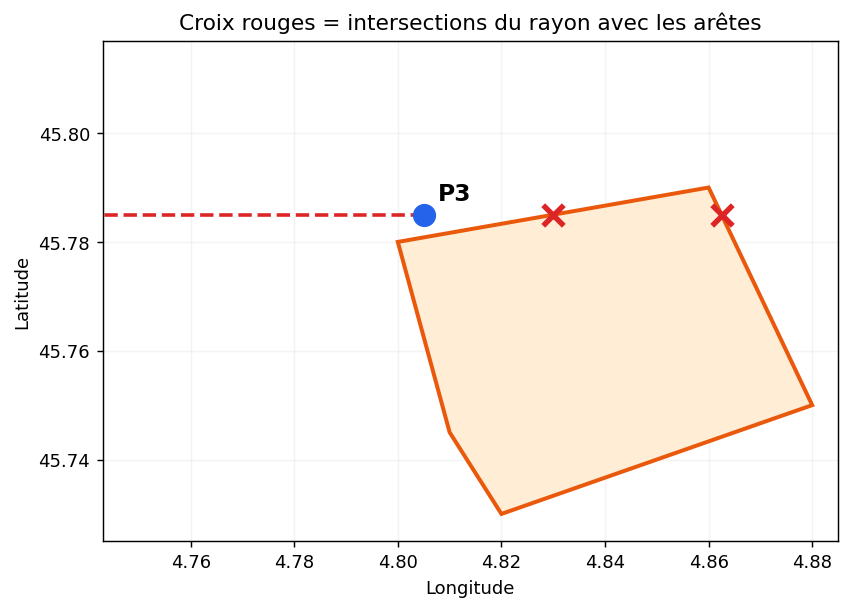

In [3]:
# Appel de la véritable fonction pour la décision ; intersections calculées pour le dessin.
p3=gps_points[2]
inside3=is_point_in_zfe(p3,polygon,bbox)
xx3=intersections_pour_dessin(p3)
fig, ax=plt.subplots(figsize=(7.3,5))
fond_polygon(ax)
ax.hlines(p3['lat'],p3['lon'],.89,colors='#dc2626',linestyles='dashed',lw=2)
ax.scatter([p3['lon']],[p3['lat']],s=140,color='#2563eb',zorder=6)
for x in xx3: ax.scatter([x],[p3['lat']],marker='x',color='#dc2626',s=130,linewidths=3,zorder=7)
ax.annotate('P3', (p3['lon'],p3['lat']),xytext=(8,8),textcoords='offset points',weight='bold',fontsize=13)
ax.set_title('Croix rouges = intersections du rayon avec les arêtes')
code_et_resultat(is_point_inside_polygon,fig,
 f"P3 : Bounding Box = {is_inside_bounding_box(p3,bbox)} ; intersections = {len(xx3)} ; résultat réel = {'IN' if inside3 else 'OUT'}",
 'ÉTAPE 2 — Ray Casting sur P3')

## 3 — Ray Casting : pourquoi **P4 déclenche une alerte** ?

Même fonction Python, **autre point GPS**. Cette fois le rayon coupe la frontière un nombre impair de fois, d'où la décision `IN`. C'est le premier point `IN` après trois points `OUT`.


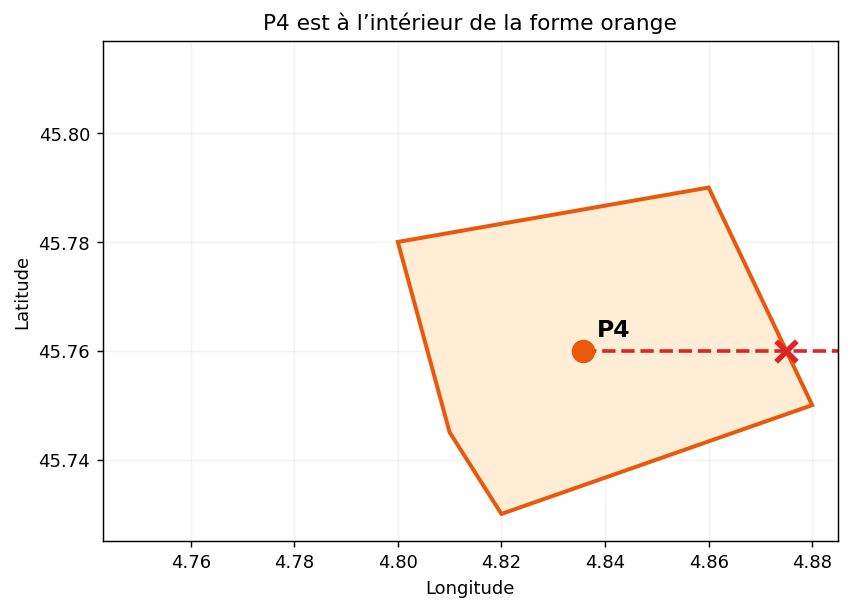

In [4]:
p4=gps_points[3]
inside4=is_point_in_zfe(p4,polygon,bbox)
xx4=intersections_pour_dessin(p4)
fig, ax=plt.subplots(figsize=(7.3,5))
fond_polygon(ax)
ax.hlines(p4['lat'],p4['lon'],4.89,colors='#dc2626',linestyles='dashed',lw=2)
ax.scatter([p4['lon']],[p4['lat']],s=145,color='#ea580c',zorder=6)
for x in xx4: ax.scatter([x],[p4['lat']],marker='x',color='#dc2626',s=130,linewidths=3,zorder=7)
ax.annotate('P4', (p4['lon'],p4['lat']),xytext=(8,8),textcoords='offset points',weight='bold',fontsize=13)
ax.set_title('P4 est à l’intérieur de la forme orange')
code_et_resultat(is_point_inside_polygon,fig,
 f"P4 : Bounding Box = {is_inside_bounding_box(p4,bbox)} ; intersections = {len(xx4)} ; résultat réel = {'IN' if inside4 else 'OUT'}",
 'ÉTAPE 3 — Ray Casting sur P4')

## 4 — Le programme n'affiche **une alerte que lors de l'entrée**

**Dans `run_geo_engine()` :** la variable `was_inside` mémorise l'état précédent. Lorsque `is_inside=True` et `was_inside=False`, la console affiche `[ALERT ZFE]`. Pour P5, le camion est toujours dans la ZFE : `[GPS IN]`.


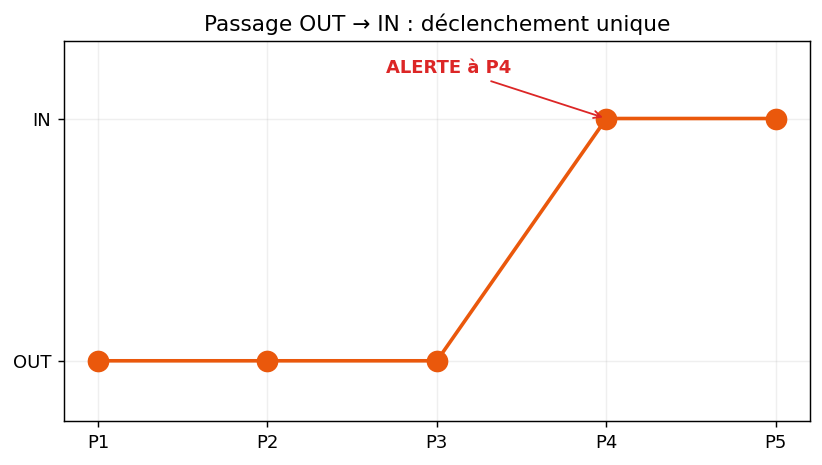

In [5]:
buffer=io.StringIO()
with redirect_stdout(buffer):
    run_geo_engine()  # vrai exécutable de src/geo/run_geo.py
sortie=buffer.getvalue()
assert '[ALERT ZFE] id=4' in sortie and sortie.count('[ALERT ZFE]') == 1
etats=[is_point_in_zfe(p,polygon,bbox) for p in gps_points]
fig,ax=plt.subplots(figsize=(7.4,3.8))
ax.plot(range(1,6),[int(x) for x in etats],color='#ea580c',marker='o',markersize=11,lw=2)
ax.set_yticks([0,1],['OUT','IN']); ax.set_xticks(range(1,6),['P1','P2','P3','P4','P5']);ax.set_ylim(-.25,1.32)
ax.grid(alpha=.2)
ax.annotate('ALERTE à P4',xy=(4,1),xytext=(2.7,1.19),arrowprops={'arrowstyle':'->','color':'#dc2626'},color='#dc2626',weight='bold')
ax.set_title('Passage OUT → IN : déclenchement unique')
code_et_resultat(run_geo_engine,fig,
 '<br>'.join(html.escape(l) for l in sortie.strip().splitlines()),'ÉTAPE 4 — Sorties de run_geo_engine()')

## 5 — Safety : **la condition Python explique le pic**

Le fichier `accelerometer_data.csv` contient dix mesures. La fonction réelle `is_harsh_braking(acc_y)` teste `acc_y < -2.5` m/s². Aucun filtre passe-bas n'est implémenté dans ce moteur.


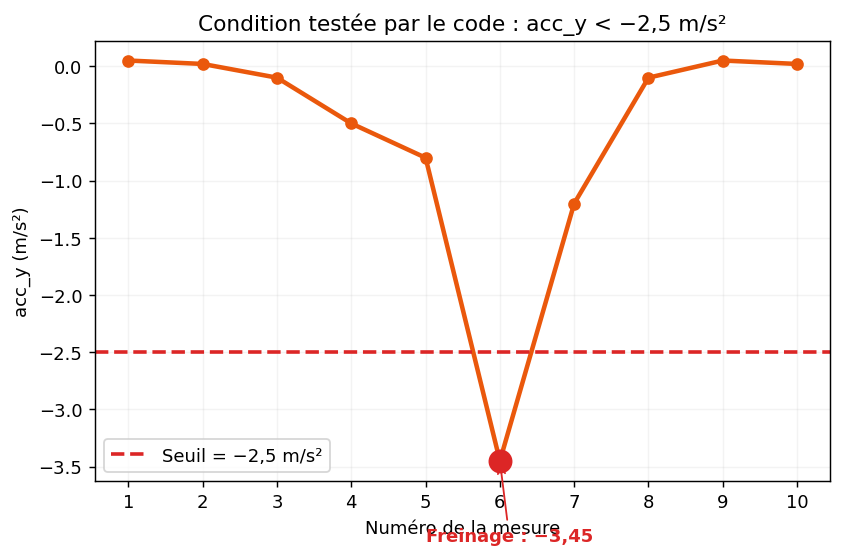

In [6]:
score = analyze_accelerometer_stream(iter_accelerometer_data('data/accelerometer_data.csv'))
xs=list(range(1,len(samples)+1))
ys=[p['acc_y'] for p in samples]
fig,ax=plt.subplots(figsize=(7.3,4.4))
ax.plot(xs,ys,color='#ea580c',marker='o',lw=2.5)
ax.axhline(HARSH_BRAKING_THRESHOLD, color='#dc2626',ls='--',lw=2,label='Seuil = −2,5 m/s²')
for i,s in enumerate(samples,1):
    if is_harsh_braking(s['acc_y']):
        ax.scatter([i],[s['acc_y']],color='#dc2626',s=150,zorder=6)
        ax.annotate('Freinage : −3,45',xy=(i,s['acc_y']),xytext=(5,-4.15),color='#dc2626',weight='bold',arrowprops={'arrowstyle':'->','color':'#dc2626'})
ax.set_xlabel('Numéro de la mesure');ax.set_ylabel('acc_y (m/s²)');ax.set_xticks(xs);ax.grid(alpha=.15);ax.legend()
ax.set_title('Condition testée par le code : acc_y < −2,5 m/s²')
code_et_resultat([is_harsh_braking,analyze_accelerometer_stream],fig,
 f"Mesures : {score['total_samples']} · freinages détectés : {score['harsh_braking_events']} · valeur : {score['events'][0]['acc_y']} m/s²",
 'ÉTAPE 5 — Détection du freinage')

## 6 — Charge simulée : **1 000 mesures, pas un benchmark matériel**

`generate_demo_data()` crée 1 000 points horodatés toutes les 0,01 seconde, soit 100 Hz *simulés*. Le même `analyze_accelerometer_stream()` produit un seul événement. Les données ne sont pas captées sur une vraie Zebra ET40.

Generated 1000 samples in data/demo_accelerometer_1000.csv



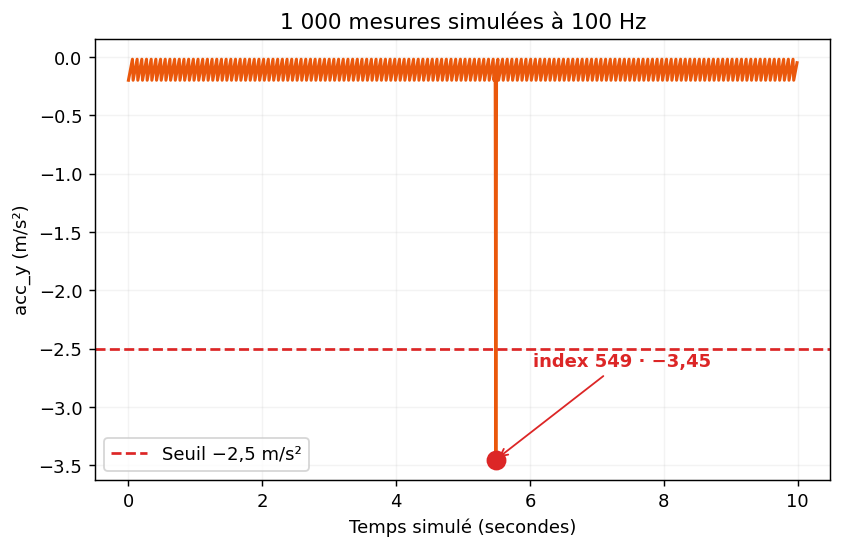

In [7]:
# Génération réelle par le script fourni, puis appel du véritable moteur Safety.
generate_demo_data()
mesures_100hz=list(iter_accelerometer_data('data/demo_accelerometer_1000.csv'))
score100=analyze_accelerometer_stream(iter_accelerometer_data('data/demo_accelerometer_1000.csv'))
fig,ax=plt.subplots(figsize=(7.3,4.4))
ax.plot([(s['timestamp']-mesures_100hz[0]['timestamp']) for s in mesures_100hz],
        [s['acc_y'] for s in mesures_100hz],color='#ea580c',linewidth=1.7)
ax.axhline(-2.5,color='#dc2626',linestyle='--',label='Seuil −2,5 m/s²')
ax.scatter([5.49],[-3.45],color='#dc2626',s=100,zorder=5)
ax.annotate('index 549 · −3,45',xy=(5.49,-3.45),xytext=(6.05,-2.65),color='#dc2626',weight='bold',arrowprops={'arrowstyle':'->','color':'#dc2626'})
ax.set_xlabel('Temps simulé (secondes)');ax.set_ylabel('acc_y (m/s²)');ax.grid(alpha=.15);ax.legend()
ax.set_title('1 000 mesures simulées à 100 Hz')
code_et_resultat(generate_demo_data,fig,
 f"Échantillons générés : {score100['total_samples']} · événement(s) détecté(s) : {score100['harsh_braking_events']}",
 'ÉTAPE 6 — Génération et traitement à 100 Hz')

## 7 — SQLite : **un événement, trois états successifs**

Dans l'archive d'industrialisation, `EventRepository.add()` enregistre l'événement ; `SyncService.sync_pending()` essaie de l'envoyer. **La simulation n'utilise aucun serveur 4G ou Cloud réel.** Le graphique présente le nombre d'événements en attente dans la vraie base SQLite temporaire.


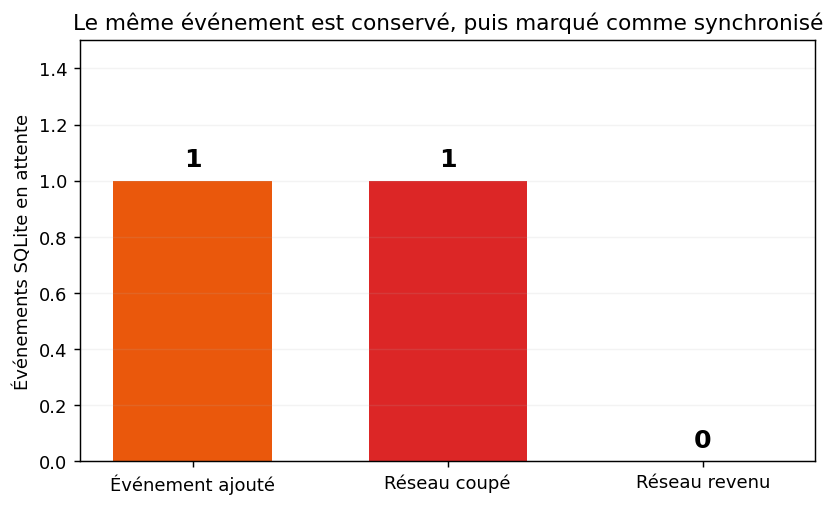

In [8]:
with tempfile.TemporaryDirectory() as temp:
    repo=EventRepository(Path(temp)/'demo.sqlite')
    evt=TelemetryEvent.harsh_braking(acc_y=-3.45, timestamp=1678880005)
    repo.add(evt)
    avant=repo.pending_count()
    def reseau_coupe(event, timeout): raise ConnectionError('Coupure 4G simulée')
    tentative=SyncService(repo,reseau_coupe,max_attempts=2).sync_pending()
    pendant=repo.pending_count()
    confirmations=[]
    def reseau_revenu(event, timeout): confirmations.append(event['id'])  # serveur simulé
    reprise=SyncService(repo,reseau_revenu).sync_pending()
    apres=repo.pending_count()
fig,ax=plt.subplots(figsize=(7.3,4.2))
bars=ax.bar(['Événement ajouté','Réseau coupé','Réseau revenu'],[avant,pendant,apres],color=['#ea580c','#dc2626','#2563eb'],width=.62)
for b,v in zip(bars,[avant,pendant,apres]): ax.text(b.get_x()+b.get_width()/2,v+.05,str(v),ha='center',fontsize=14,weight='bold')
ax.set_ylim(0,1.5);ax.set_ylabel('Événements SQLite en attente');ax.set_title('Le même événement est conservé, puis marqué comme synchronisé')
ax.grid(axis='y',alpha=.15)
code_et_resultat([EventRepository.add,SyncService.sync_pending],fig,
 f"En attente : {avant} → {pendant} → {apres} · échec simulé : {tentative['failed']} · synchronisés après reprise : {reprise['synced']}",
 'ÉTAPE 7 — Sauvegarde et synchronisation différée')

## 8 — Gestion des erreurs : **le problème est signalé clairement**

Le vrai `load_json_file()` génère `FileNotFoundError` si le fichier n'existe pas. Le script `run_geo_engine()` intercepte cette exception pour afficher `[ERROR]` au lieu de laisser le programme se terminer brutalement.


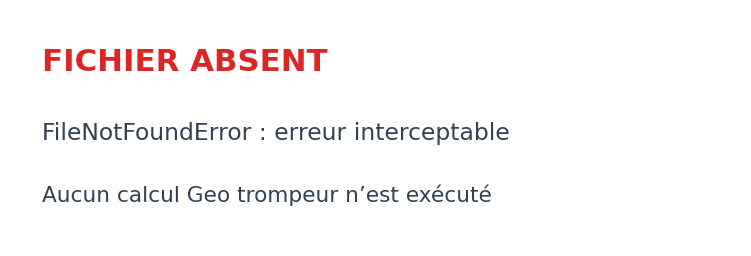

In [9]:
message=''
try:
    load_json_file('data/fichier_inexistant.json')
except FileNotFoundError as error:
    message=str(error)
fig,ax=plt.subplots(figsize=(7.2,2.3));ax.axis('off')
ax.text(.04,.75,'FICHIER ABSENT',weight='bold',fontsize=17,color='#dc2626',transform=ax.transAxes)
ax.text(.04,.45,'FileNotFoundError : erreur interceptable',fontsize=13,color='#334155',transform=ax.transAxes)
ax.text(.04,.18,'Aucun calcul Geo trompeur n’est exécuté',fontsize=12,color='#334155',transform=ax.transAxes)
code_et_resultat(load_json_file,fig,html.escape(message),'ÉTAPE 8 — Entrée manquante')

---
### Conclusion à dire pendant la vidéo

« Les deux fonctions du POC ont été exécutées à partir des fichiers de l’énoncé. La Bounding Box élimine rapidement les positions éloignées ; le Ray Casting différencie P3 de P4, d'où l’alerte d'entrée. Le moteur Safety détecte le seul freinage à −3,45 m/s² et le traitement de 1 000 mesures simulées réutilise exactement la même fonction. Enfin, SQLite conserve l’événement pendant une coupure réseau simulée. Il reste à valider les capteurs, le GPS et les performances sur la tablette réelle. »

**Références de code local :** `src/geo/geo_engine.py`, `src/geo/run_geo.py`, `src/safety/safety_engine.py`, `scripts/generate_demo_data.py`, `src/storage/event_repository.py`, `src/sync/sync_service.py`.